# 04: Visualização Multi-Planar e Fusão PET/CT

**Objetivo:** Explorar os três planos anatômicos ortogonais (Axial, Coronal, Sagital), aplicar janelamento tomográfico (Windowing em HU) para realçar tecidos moles e o coração, e realizar a fusão de imagens térmicas de PET sobrepostas à tomografia com canal alfa (transparência).

---

## 1. Importações e Configuração

In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path("..").resolve()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import numpy as np
import SimpleITK as sitk
import matplotlib.pyplot as plt

import config
from src import io_utils, registration, visualization

print("Módulos importados com sucesso!")

Módulos importados com sucesso!


## 2. Preparando os Volumes em Memória

Carregamos e reamostramos os exames do paciente `'0001'`.

In [2]:
patient_id = "0001"
caminhos = config.get_caminhos(patient_id)

if caminhos["CT"].exists() and caminhos["PET"].exists():
    ct_img = io_utils.load_sitk_image(caminhos["CT"])
    pet_img = io_utils.load_sitk_image(caminhos["PET"])
    mask_img = io_utils.load_sitk_image(caminhos["Mascara_Cardiaca"]) if caminhos["Mascara_Cardiaca"].exists() else None
    
    reg = registration.full_pet_ct_registration_pipeline(ct_img, pet_img, mask_img, verbose=False)
    
    ct_arr = io_utils.sitk_to_numpy(ct_img)
    pet_arr = io_utils.sitk_to_numpy(reg["pet_registered"])
    mask_arr = io_utils.sitk_to_numpy(reg["mask_resampled"]) if reg["mask_resampled"] else None
    
    print("Volumes prontos para visualização! Shape:", ct_arr.shape)
else:
    print("Dados NIfTI não encontrados localmente.")

Volumes prontos para visualização! Shape: (365, 512, 512)


## 3. Cortes Ortogonais nos Três Planos (Axial, Coronal e Sagital)

Visualizamos o CT em janela de tecido mole (WL=40, WW=400) e o PET com colormap `'hot'`.

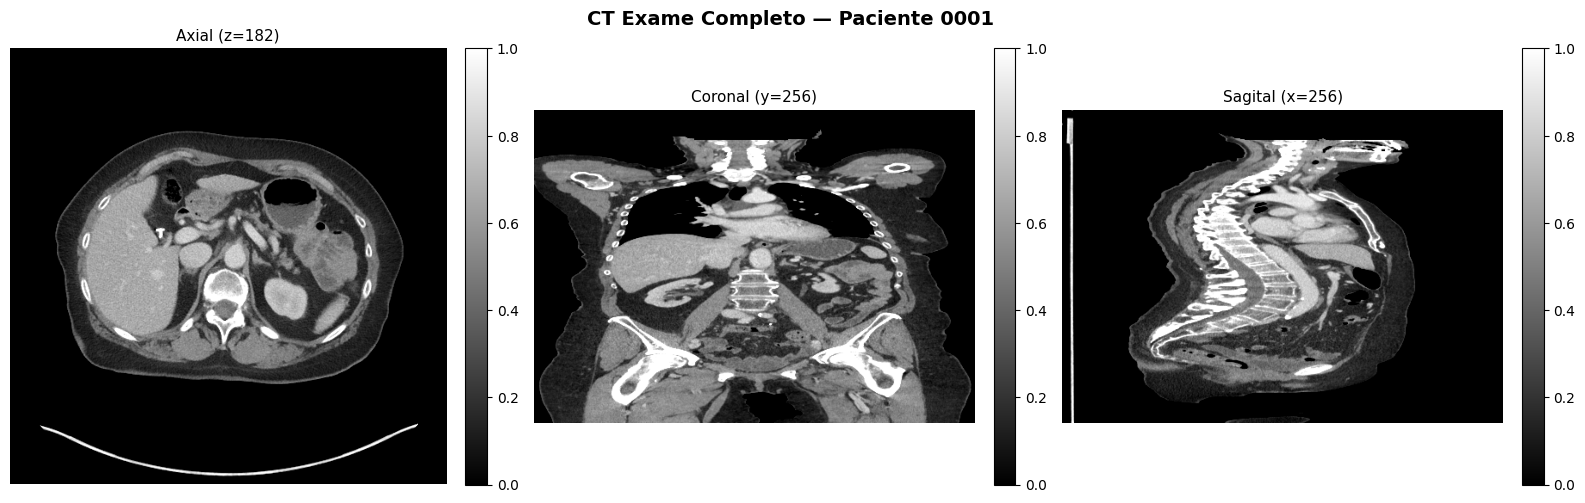

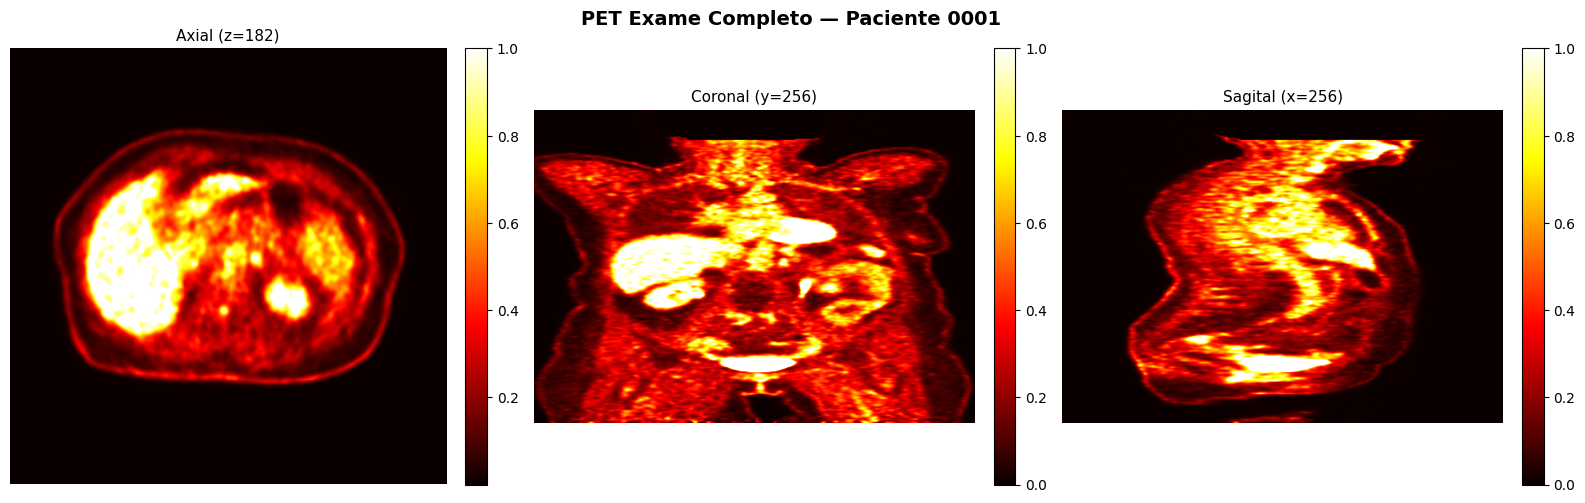

In [3]:
if 'ct_arr' in locals():
    # CT nos 3 planos
    fig_ct = visualization.plot_three_planes(
        ct_arr, 
        title=f"CT Exame Completo — Paciente {patient_id}",
        wl=40, ww=400
    )
    plt.show()
    
    # PET nos 3 planos
    p99_pet = float(np.percentile(pet_arr[pet_arr > 0], 99.0))
    fig_pet = visualization.plot_three_planes(
        pet_arr,
        title=f"PET Exame Completo — Paciente {patient_id}",
        cmap="hot",
        wl=p99_pet / 2.0, ww=p99_pet
    )
    plt.show()

## 4. Fusão PET/CT Multi-Planar (Alpha Blending)

Sobrepomos a atividade molecular do PET (colormap colorido) sobre a base anatômica em tons de cinza do CT com transparência adaptativa.

C:\Users\estela.ribeiro\JupyterNotebooks\pet_ct_primeiros_passos\src\visualization.py:456: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


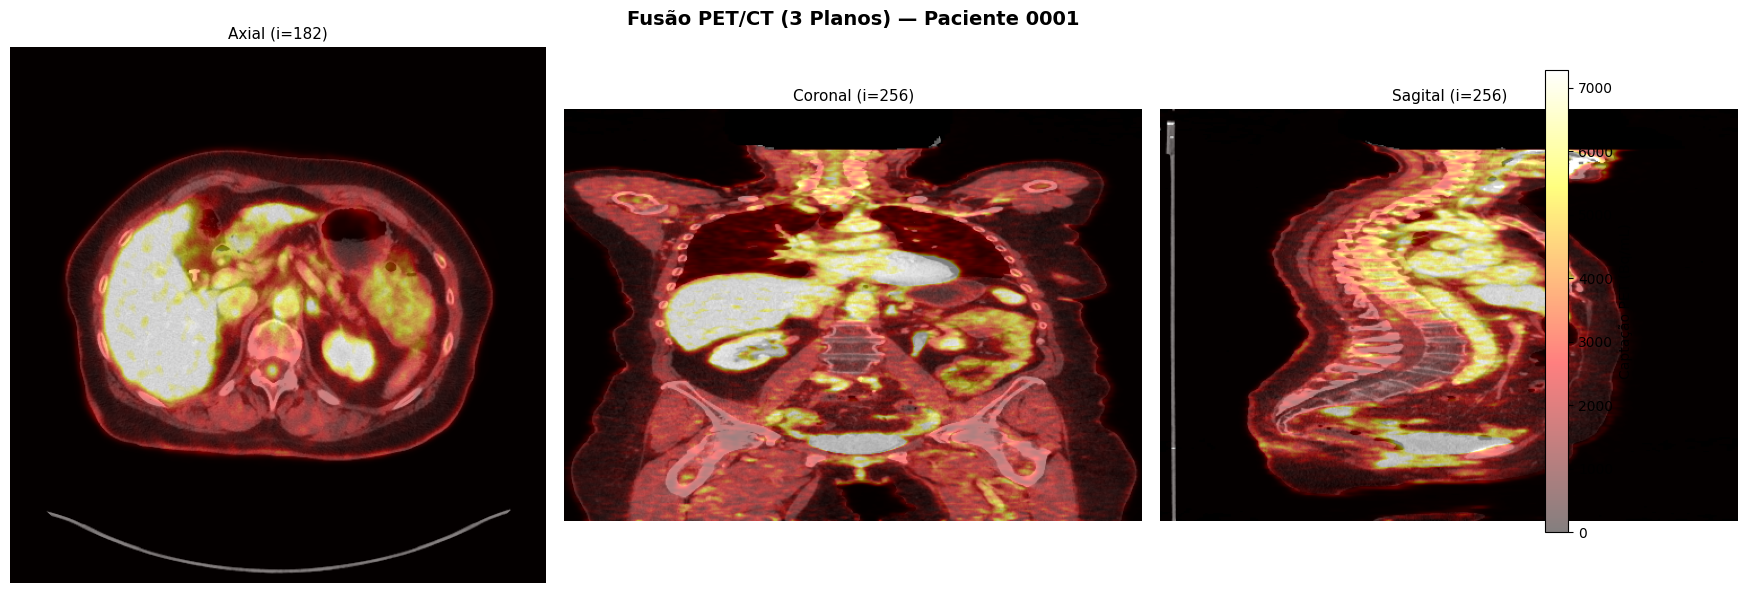

In [4]:
if 'ct_arr' in locals():
    fig_fusao = visualization.plot_pet_ct_fusion_three_planes(
        ct_volume=ct_arr,
        pet_volume=pet_arr,
        title=f"Fusão PET/CT (3 Planos) — Paciente {patient_id}",
        pet_vmax=p99_pet
    )
    plt.show()

## 5. Foco Cardíaco: Bounding Box 3D e Painel em 4 Colunas

Recortamos automaticamente o volume ao redor do miocárdio e exibimos lado a lado: CT, PET, Fusão e Máscara Anatômica.

C:\Users\estela.ribeiro\JupyterNotebooks\pet_ct_primeiros_passos\src\visualization.py:940: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


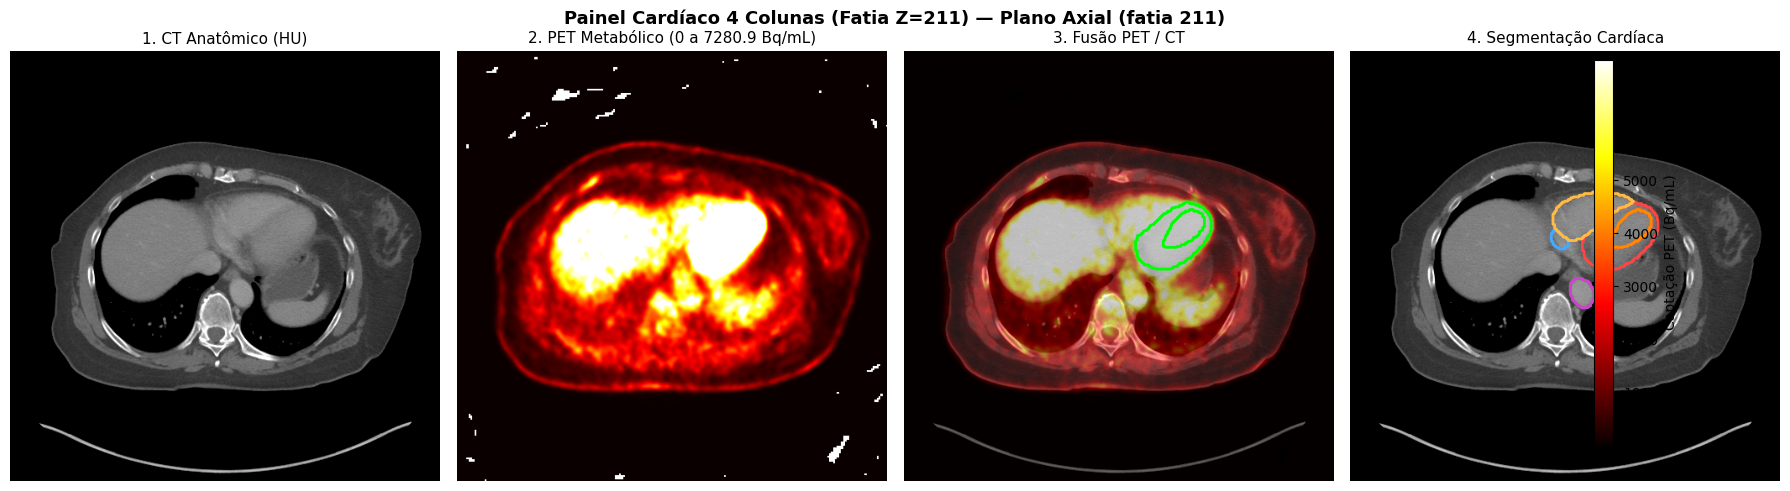

In [5]:
if 'mask_arr' in locals() and mask_arr is not None:
    # Localizar fatia Z de maior volume do miocárdio
    vox_mio = np.sum(mask_arr == config.LABEL_MIOCARDIO, axis=(1, 2))
    z_pico = int(np.argmax(vox_mio))
    
    fig_panel = visualization.plot_cardiac_fusion_panel(
        ct_volume=ct_arr,
        pet_volume=pet_arr,
        mask_volume=mask_arr,
        slice_idx=z_pico,
        target_labels=list(config.ROTULOS_CORACAO.keys()),
        mask_colors=config.CORES_CARDIACAS,
        pet_vmax=p99_pet,
        title=f"Painel Cardíaco 4 Colunas (Fatia Z={z_pico})"
    )
    plt.show()